<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/earth-data/index.html">Earth Data in Python and R</a><span class="sep">·</span>Part 3 · Regridding</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Assumes <a href="/blogs/xarray-basics/dimensions_coordinates_attributes.html">Dimensions, coordinates and attributes</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Regridding is routine in Earth-system work, the method is often chosen by habit, and a wrong choice changes the answer silently. What decides it is what the number in a cell means. A temperature is a value at a place; bilinear interpolation reads it at each target centre from the four nearest source centres, fine when the field is smooth at the source resolution. An emission flux or a precipitation rate is a cell average whose area integral is a budget; first-order conservative remapping gives each target cell the area-weighted mean of the source cells it overlaps, preserving that integral exactly. Regridding a synthetic global emission field from 0.25° to 1.875° × 2.5°, bilinear interpolation never reads 94.7% of the source cells, drops 97 of 100 point sources and loses 2.6% of the total; conservative remapping keeps it to within $2\times10^{-16}$. Afterwards you can say which method a field needs and check the choice with one sum.
:::

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter

# fallcolor is the site's colour module at the repo root, not an installed package.
sys.path.insert(
    0,
    str(
        next(
            p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "fallcolor.py").exists()
        )
    ),
)
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
warnings.formatwarning = lambda msg, cat, *_, **__: (
    f"{cat.__name__}: {msg}\n"
)  # no file paths in output
rng = np.random.default_rng(2026)

## What a cell value means

A gridded file rarely says which of three things its cell values are:

- **a value at a point**, such as a temperature at a station or a grid node (a finite-volume model's temperature is a cell mean);
- **a cell mean of a density**, such as a precipitation rate or emission flux in $\text{kg m}^{-2}\text{ s}^{-1}$, or a cropland fraction;
- **a cell total**, such as tonnes of maize produced in the cell.

The first two are both intensive, so "intensive or extensive" is not the test. The test is whether anyone will multiply the field by cell area and add it up. If so, regridding must preserve

$$Q = \sum_i \bar q_i A_i, \tag{1}$$

where $\bar q_i$ is the mean density over source cell $i$ and $A_i$ its area. A method is **conservative** if the same sum over the target cells equals $Q$. A cell total must first be divided by its cell's area.

## Both methods in one dimension

**Linear interpolation**, bilinear in one dimension, evaluates the target at its centre $x_j$:

$$\bar q_j = (1 - t)\, q_k + t\, q_{k+1}, \qquad t = \frac{x_j - x_k}{x_{k+1} - x_k}, \tag{2}$$

where $x_k \le x_j < x_{k+1}$ are the neighbouring source centres and $q_k$, $q_{k+1}$ their values. Cell widths appear nowhere.

**First-order conservative remapping** gives target cell $j$ the overlap-weighted mean of the source cells it touches:

$$\bar q_j = \frac{1}{A_j} \sum_i |S_i \cap T_j|\, \bar q_i, \tag{3}$$

where $S_i$ and $T_j$ are source cell $i$ and target cell $j$, $|S_i \cap T_j|$ is the size of their overlap (a length here, an area in 2-D) and $A_j = |T_j|$. Then $\sum_j A_j \bar q_j = \sum_i \bar q_i \sum_j |S_i \cap T_j| = \sum_i \bar q_i A_i = Q$, since the target cells cover each source cell exactly once. Conservation is exact when both grids cover the same domain; where the target covers less (a regional grid, an ocean mask), that part of $Q$ is lost. "First order" means the field is constant within each source cell; Jones gives first- and second-order schemes for any grid on a sphere[^1].

Each method is a weight matrix $\mathbf{W}$:

In [2]:
def linear_weights(src_centres, points):
    """Row r holds the linear-interpolation weights giving the value at points[r]."""
    k = np.clip(np.searchsorted(src_centres, points) - 1, 0, len(src_centres) - 2)
    t = np.clip((points - src_centres[k]) / (src_centres[k + 1] - src_centres[k]), 0, 1)
    W = np.zeros((len(points), len(src_centres)))
    W[np.arange(len(points)), k], W[np.arange(len(points)), k + 1] = 1 - t, t
    return W


def conservative_weights(src_edges, tgt_edges):
    """Row j holds the fraction of target cell j that each source cell covers."""
    lo = np.maximum(tgt_edges[:-1, None], src_edges[None, :-1])
    hi = np.minimum(tgt_edges[1:, None], src_edges[None, 1:])
    return np.clip(hi - lo, 0, None) / np.diff(tgt_edges)[:, None]

The test: a smooth bump plus a point source of 40 in one cell, from 120 fine cells on $[0, 1]$ to 9 coarse ones (ratio $13.\overline{3}$).

In [3]:
src_edges, tgt_edges = (
    np.linspace(0, 1, 121),
    np.linspace(0, 1, 10),
)  # 120 fine, 9 coarse cells
src_x, tgt_x = (
    (src_edges[:-1] + src_edges[1:]) / 2,
    (tgt_edges[:-1] + tgt_edges[1:]) / 2,
)
dx_src, dx_tgt = 1 / 120, 1 / 9
L, C = linear_weights(src_x, tgt_x), conservative_weights(src_edges, tgt_edges)
smooth = 1 + 2 * np.exp(-(((src_x - 0.35) / 0.15) ** 2))
q = smooth.copy()
q[50] += 40  # a point source filling one fine cell
print(
    "linear weights match np.interp:",
    np.allclose(L @ q, np.interp(tgt_x, src_x, q)),
    f"| spike cell holds {q[50]:.1f}",
)
for name, field in [("smooth only", smooth), ("smooth + spike", q)]:
    for method, W in [("linear", L), ("conservative", C)]:
        got, true = (W @ field).sum() * dx_tgt, field.sum() * dx_src
        print(
            f"{name:14s} {method:12s} total {got:.4f}, true {true:.4f}, relative error {got / true - 1:+.2e}"
        )

linear weights match np.interp: True | spike cell holds 42.6
smooth only    linear       total 1.5317, true 1.5315, relative error +1.13e-04
smooth only    conservative total 1.5315, true 1.5315, relative error +0.00e+00
smooth + spike linear       total 1.5317, true 1.8648, relative error -1.79e-01
smooth + spike conservative total 1.8648, true 1.8648, relative error -5.55e-16


Linear interpolation loses 18% of the total: no coarse centre has fine cell 50 as a neighbour, so the spike is never read. Moving the spike through every fine cell:

In [4]:
kept_lin, kept_con = L.sum(axis=0) * dx_tgt / dx_src, C.sum(axis=0) * dx_tgt / dx_src
print(
    f"linear: spike lost in {np.mean(kept_lin == 0):.0%} of positions; at most {kept_lin.max():.2f} times kept"
)
print(
    f"conservative: kept fraction between {kept_con.min():.12f} and {kept_con.max():.12f}"
)

linear: spike lost in 85% of positions; at most 11.11 times kept
conservative: kept fraction between 1.000000000000 and 1.000000000000


Linear interpolation loses the spike in 85% of positions and elsewhere keeps up to 11.11 times its integral: a coarse centre beside the spike hands its value to a cell $13.\overline{3}$ times wider. Conservative remapping keeps exactly one spike's worth, at a cost seen coarse to fine (Figure 1c): it cannot invent structure inside a coarse cell, so it returns a staircase.

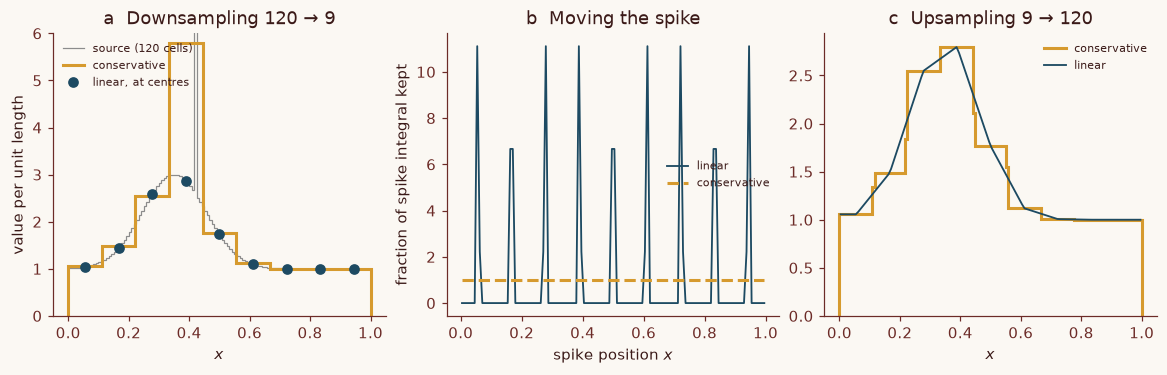

In [5]:
coarse = C @ smooth  # for panel c, the reverse trip: 9 cells onto 120
up_lin, up_con = (
    linear_weights(tgt_x, src_x) @ coarse,
    conservative_weights(tgt_edges, src_edges) @ coarse,
)
fig, (a, b, c) = plt.subplots(1, 3, figsize=(10.5, 3.3), constrained_layout=True)
c_lin, c_con = "C0", "C1"  # first two colours of the fall "default" set
a.stairs(q, src_edges, color="0.55", lw=0.8, label="source (120 cells)")
a.stairs(C @ q, tgt_edges, color=c_con, lw=2, label="conservative")
a.plot(tgt_x, L @ q, "o", color=c_lin, label="linear, at centres")
a.set(
    ylim=(0, 6),
    xlabel="$x$",
    ylabel="value per unit length",
    title="a  Downsampling 120 → 9",
)
b.plot(src_x, kept_lin, color=c_lin, lw=1.2, label="linear")
b.plot(src_x, kept_con, color=c_con, lw=2, ls="--", label="conservative")
b.set(
    xlabel="spike position $x$",
    ylabel="fraction of spike integral kept",
    title="b  Moving the spike",
)
c.stairs(up_con, src_edges, color=c_con, lw=2, label="conservative")
c.plot(src_x, up_lin, color=c_lin, lw=1.2, label="linear")
c.set(xlabel="$x$", title="c  Upsampling 9 → 120")
for ax in (a, b, c):
    ax.legend(fontsize=7, loc="upper left" if ax is a else "best")
plt.show()

<strong>Figure 1 | Linear interpolation samples the field; conservative remapping averages it.</strong>
<strong>a</strong>, The 120-cell field (grey; the spike, clipped, reaches 42.6) on 9 cells, linear at target centres (dots) and conservative (steps).
<strong>b</strong>, Fraction of the spike's integral kept, by spike position.
<strong>c</strong>, The smooth bump's 9-cell conservative result, regridded back onto 120 cells.

## On the sphere

### Exact cell areas

The area element on a sphere of radius $R$ is $dA = R^2 \cos\varphi \, d\varphi \, d\lambda$, with latitude $\varphi$ and longitude $\lambda$ in radians. Integrating over a cell between meridians $\lambda_w, \lambda_e$ and parallels $\varphi_s, \varphi_n$ gives, exactly,

$$A = R^2 (\lambda_e - \lambda_w)(\sin\varphi_n - \sin\varphi_s), \tag{4}$$

as in the mass diagnostic of [Regridding crop data for climate models](../r-regridding/index.qmd). In $\mu = \sin\varphi$ the area element is $R^2\, d\mu\, d\lambda$, so the sphere is a flat rectangle in $(\lambda, \mu)$ and the overlap of two latitude–longitude cells has area $\lambda$ overlap times $\mu$ overlap. Conservative remapping between such grids is eq. (3) in $\lambda$ and in $\mu$: the same `conservative_weights`, given the sines of the latitude edges.

We use the unit sphere ($R = 1$, areas in steradians); $R^2$ cancels from relative errors. The target has the R module's 96 × 144 cells, here uniform.

In [6]:
def cell_area(lat_e, lon_e):
    """Eq. (4) on the unit sphere, in steradians."""
    return np.outer(np.diff(np.sin(np.radians(lat_e))), np.diff(np.radians(lon_e)))


lat_e_s, lon_e_s = (
    np.linspace(-90, 90, 721),
    np.linspace(-180, 180, 1441),
)  # 0.25 degree source
lat_e_t, lon_e_t = (
    np.linspace(-90, 90, 97),
    np.linspace(-180, 180, 145),
)  # 1.875 x 2.5 degree target
lat_s, lon_s, lat_t, lon_t = [
    (e[:-1] + e[1:]) / 2 for e in (lat_e_s, lon_e_s, lat_e_t, lon_e_t)
]  # centres
A_s, A_t = cell_area(lat_e_s, lon_e_s), cell_area(lat_e_t, lon_e_t)
for name, A in [("source", A_s), ("target", A_t)]:
    print(
        f"{name}: {A.size:>7d} cells, total area / 4 pi - 1 = {A.sum() / (4 * np.pi) - 1:+.1e}"
    )
print(f"mean target / source cell area: {A_t.mean() / A_s.mean():.0f}")

source: 1036800 cells, total area / 4 pi - 1 = +0.0e+00
target:   13824 cells, total area / 4 pi - 1 = +0.0e+00
mean target / source cell area: 75


### A global emission field

The field is a synthetic emission flux density: sharp-edged continents plus 100 point sources, each adding 200 to one cell.

In [7]:
blobs = gaussian_filter(
    rng.standard_normal((720, 1440)), sigma=40, mode=("nearest", "wrap")
)
land = blobs > np.quantile(blobs, 0.7)
flux = land * (1 + 0.5 * np.cos(np.radians(lat_s)))[:, None]
sources = rng.choice(np.flatnonzero(land), size=100, replace=False)
flux.flat[sources] += 200
print(
    f"land on {land.mean():.0%} of cells; point sources carry "
    f"{200 * A_s.flat[sources].sum() / np.sum(flux * A_s):.0%} of the total"
)

land on 30% of cells; point sources carry 4% of the total


Bilinear is linear along latitude, then longitude:

$$\bar{\mathbf{q}}_T = \mathbf{W}_\varphi\, \bar{\mathbf{q}}_S\, \mathbf{W}_\lambda^{\top}, \tag{5}$$

where $\bar{\mathbf{q}}_S$ and $\bar{\mathbf{q}}_T$ are the source and target fields as latitude × longitude matrices and $\mathbf{W}_\varphi$, $\mathbf{W}_\lambda$ the 1-D weights. Conservative remapping has the same form, with eq. (3) weights in $\mu$ and $\lambda$.

In [8]:
B_lat, B_lon = (
    linear_weights(lat_s, lat_t),
    linear_weights(lon_s, lon_t),
)  # in latitude, longitude
mu_s, mu_t = np.sin(np.radians(lat_e_s)), np.sin(np.radians(lat_e_t))
C_lat, C_lon = (
    conservative_weights(mu_s, mu_t),
    conservative_weights(lon_e_s, lon_e_t),
)  # in mu, longitude
bil, con = B_lat @ flux @ B_lon.T, C_lat @ flux @ C_lon.T
lat_g, lon_g = np.meshgrid(lat_t, lon_t, indexing="ij")
ref = RegularGridInterpolator((lat_s, lon_s), flux, method="linear")((lat_g, lon_g))
print(
    f"bilinear vs scipy: max |difference| {np.abs(bil - ref).max():.1e}, field max {flux.max():.0f}"
)
true = np.sum(flux * A_s)
for name, field in [("bilinear", bil), ("conservative", con)]:
    got = np.sum(field * A_t)
    print(
        f"{name:12s} total {got:.6f}, source {true:.6f}, relative error {(got - true) / true:+.2e}"
    )

bilinear vs scipy: max |difference| 3.6e-15, field max 201
bilinear     total 4.784580, source 4.910215, relative error -2.56e-02
conservative total 4.910215, source 4.910215, relative error -1.81e-16


Bilinear loses 2.6% of the total. To see where, define the **reach** of source cell $i$, the fraction of its integral that arrives on the target grid, as $\sum_j A_j W_{ji} / A_i$, with $W_{ji}$ its combined 2-D weight in target cell $j$:

In [9]:
reach_bil, reach_con = (B_lat.T @ A_t @ B_lon) / A_s, (C_lat.T @ A_t @ C_lon) / A_s
print(
    f"conservative: max |reach - 1| over all source cells {np.abs(reach_con - 1).max():.1e}"
)
print(f"bilinear: {np.mean(reach_bil == 0):.1%} of source cells are never read")
r = reach_bil.flat[sources]
print(
    f"bilinear, 100 point sources: {np.sum(r == 0)} dropped, the rest kept {np.sort(r[r > 0]).round(1)} times"
)

conservative: max |reach - 1| over all source cells 7.2e-14
bilinear: 94.7% of source cells are never read
bilinear, 100 point sources: 97 dropped, the rest kept [ 9.3 10.  28.2] times


Each bilinear value uses four source cells while a target cell covers 75, so 94.7% of source cells are never read. Whether a power plant survives depends on where it sits: 97 of 100 vanish, and three are over-weighted up to 28.2-fold. At a coast, bilinear takes whichever side its four points fall on; conservative weights by land fraction.

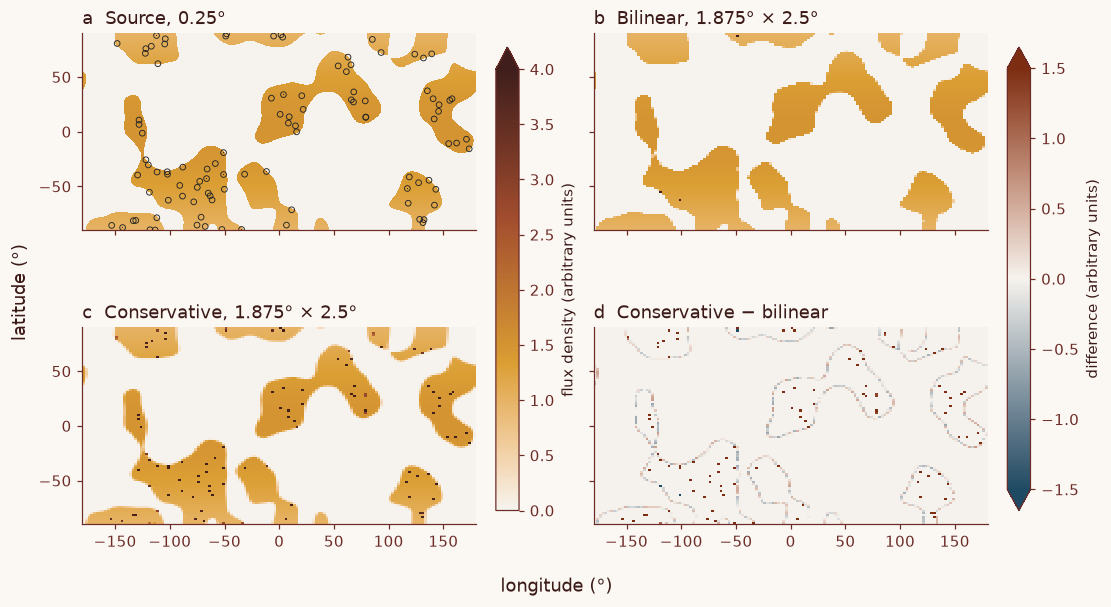

In [10]:
fig, axes = plt.subplots(
    2, 2, figsize=(10, 5.6), constrained_layout=True, sharex=True, sharey=True
)
for ax, x, y, z, title in [
    (axes[0, 0], lon_e_s, lat_e_s, flux, "a  Source, 0.25°"),
    (axes[0, 1], lon_e_t, lat_e_t, bil, "b  Bilinear, 1.875° × 2.5°"),
    (axes[1, 0], lon_e_t, lat_e_t, con, "c  Conservative, 1.875° × 2.5°"),
]:
    m = ax.pcolormesh(x, y, z, cmap="fall.ember", vmin=0, vmax=4)
    ax.set_title(title, loc="left")
fig.colorbar(
    m, ax=axes[:, 0], label="flux density (arbitrary units)", extend="max", shrink=0.8
)
axes[0, 0].scatter(
    lon_s[sources % 1440], lat_s[sources // 1440], s=14, fc="none", ec="0.15", lw=0.6
)
m = axes[1, 1].pcolormesh(
    lon_e_t,
    lat_e_t,
    con - bil,
    cmap="fall.tide",
    norm=fallcolor.palette.centered(con - bil, vmax=1.5),
)
axes[1, 1].set_title("d  Conservative − bilinear", loc="left")
fig.colorbar(
    m, ax=axes[:, 1], label="difference (arbitrary units)", extend="both", shrink=0.8
)
plt.setp(axes.flat, aspect="equal")
fig.supxlabel("longitude (°)"), fig.supylabel("latitude (°)")
plt.show()

<strong>Figure 2 | Bilinear drops most point sources; conservative keeps every one.</strong>
<strong>a</strong>, Source, circles marking point sources. <strong>b</strong>, Bilinear. <strong>c</strong>, Conservative; a–c share one scale, clipped at 4.
<strong>d</strong>, Conservative minus bilinear, clipped at ±1.5: positive at dropped point sources, negative at the three over-weighted ones, both signs along coasts.

## When bilinear is fine

Take an intensive field smooth at the source resolution: a temperature falling from 288 K at the equator to 248 K at the poles, plus a longitude wave of up to 3 K.

In [11]:
phi, lam = np.radians(lat_s)[:, None], np.radians(lon_s)[None, :]
temp = 288 - 40 * np.sin(phi) ** 2 + 3 * np.cos(3 * lam) * np.cos(phi)
t_bil, t_con = B_lat @ temp @ B_lon.T, C_lat @ temp @ C_lon.T
print(f"max |bilinear - conservative| = {np.abs(t_bil - t_con).max():.4f} K")
for name, field, A in [
    ("source", temp, A_s),
    ("bilinear", t_bil, A_t),
    ("conservative", t_con, A_t),
]:
    print(f"{name:12s} area-weighted mean {np.sum(field * A) / A.sum():.5f} K")

max |bilinear - conservative| = 0.0272 K
source       area-weighted mean 274.66665 K
bilinear     area-weighted mean 274.66543 K
conservative area-weighted mean 274.66665 K


The methods differ by at most 0.027 K, and bilinear moves the area-weighted mean by $1.2\times10^{-3}$ K. Either is fine; bilinear gives the value *at* the target centre, as a station comparison wants.

Cell totals regridded as they stand break both methods: each target cell receives a mean of source-cell totals, about $1/75$ of what it should hold.

In [12]:
per_cell = flux * A_s  # e.g. tonnes in each cell
wrong = C_lat @ per_cell @ C_lon.T  # regridded as if it were a density
right = (C_lat @ (per_cell / A_s) @ C_lon.T) * A_t  # to density, regrid, back to totals
print(f"totals regridded directly: {wrong.sum() / per_cell.sum():.4f} of the true sum")
print(f"via density:               {right.sum() / per_cell.sum():.12f} of the true sum")

totals regridded directly: 0.0133 of the true sum
via density:               1.000000000000 of the true sum


Rescaling the result to the original global sum, a common fallback, repairs the global number but not where the mass sits. The rule, in order:

1. **Is the value a total per cell?** Convert it to a density first, whatever method follows.
2. **Will anyone integrate it over area**, for a budget? Use conservative remapping.
3. **Is the target coarser, with structure at the source scale** such as coastlines, point sources or convective rain? Use conservative, even for an intensive field: bilinear reads four points of each coarse cell.
4. **Otherwise**, for a smooth intensive field or a target at least as fine as the source, bilinear is fine and smoother than first-order conservative.

Then compare $\sum \bar q A$ on both grids: it misses misplaced mass but catches every lost or invented total.

## Key takeaways

- Choose by what a cell value means. Bilinear ignores cell size and, downsampling, skips most source cells.
- First-order conservative remapping conserves $\sum \bar q A$ exactly; upsampled, it is a staircase.
- A latitude–longitude cell has area $R^2(\lambda_e - \lambda_w)(\sin\varphi_n - \sin\varphi_s)$; in $\sin\varphi$ the grid is a flat rectangle.
- Convert cell totals to densities first, and check the area-weighted total before and after.

### Data and code

Synthetic fields from `numpy.random.default_rng(2026)`; NumPy, SciPy, Matplotlib. Curvilinear or unstructured grids need a remapping library rather than these separable weights.

## References

[^1]: Jones, P. W. First- and second-order conservative remapping schemes for grids in spherical coordinates. *Mon. Weather Rev.* **127**, 2204–2210 (1999). https://doi.org/10.1175/1520-0493(1999)127%3C2204:FASOCR%3E2.0.CO;2

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/r-regridding/index.html"><span>Previous</span>Regridding crop data for climate models</a><a class="mf-up" href="/series/earth-data/index.html"><span>Series</span>Earth Data in Python and R</a><a class="mf-next" href="/blogs/regional-analysis-r/index.html"><span>Next</span>Regional analysis in R</a></div>
<!-- CURRICULUM_FOOTER_END -->